Decision Trees

Membaca dan menyiapkan dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = pd.read_csv("data/WineQT.csv")

print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
X = data.drop(columns=["quality", "Id"])
y = data["quality"]

print("Jumlah fitur:", X.shape[1])
print("\nDistribusi kelas:")
print(y.value_counts().sort_index())

Jumlah fitur: 11

Distribusi kelas:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


Membagi data dan membuat Decision Tree

Data dibagi menjadi data latih dan data uji. Parameter `stratify=y` membantu mempertahankan proporsi kelas pada kedua bagian.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print("Jumlah node:", tree.tree_.node_count)
print("Kedalaman pohon:", tree.get_depth())

Jumlah node: 497
Kedalaman pohon: 17


Evaluasi model awal

Bandingkan performa pada data latih dan data uji. Jika hasil data latih jauh lebih baik daripada data uji, model mungkin mengalami **overfitting**.

In [4]:
train_pred = tree.predict(X_train)
test_pred = tree.predict(X_test)

print("Accuracy data latih:", round(accuracy_score(y_train, train_pred), 4))
print("Accuracy data uji:", round(accuracy_score(y_test, test_pred), 4))

print("\nClassification Report (data uji):")
print(classification_report(y_test, test_pred, zero_division=0))

Accuracy data latih: 1.0
Accuracy data uji: 0.6288

Classification Report (data uji):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.17      0.14      0.15         7
           5       0.68      0.71      0.70        97
           6       0.63      0.61      0.62        92
           7       0.58      0.62      0.60        29
           8       0.00      0.00      0.00         3

    accuracy                           0.63       229
   macro avg       0.34      0.35      0.34       229
weighted avg       0.62      0.63      0.62       229



Mengatur kompleksitas pohon

Salah satu cara mengurangi overfitting adalah membatasi `max_depth`. GridSearchCV mencoba beberapa kombinasi kedalaman dan memilih model berdasarkan cross-validation.

In [5]:
parameter_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    parameter_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_tree = grid_search.best_estimator_

print("Parameter terbaik:", grid_search.best_params_)
print("Jumlah node:", best_tree.tree_.node_count)
print("Kedalaman pohon:", best_tree.get_depth())

Parameter terbaik: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}
Jumlah node: 57
Kedalaman pohon: 5


In [6]:
best_pred = best_tree.predict(X_test)

print("Accuracy model awal:", round(accuracy_score(y_test, test_pred), 4))
print("Accuracy model terbaik:", round(accuracy_score(y_test, best_pred), 4))
print("\nClassification Report model terbaik:")
print(classification_report(y_test, best_pred, zero_division=0))

Accuracy model awal: 0.6288
Accuracy model terbaik: 0.5939

Classification Report model terbaik:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.64      0.78      0.71        97
           6       0.59      0.53      0.56        92
           7       0.42      0.38      0.40        29
           8       0.00      0.00      0.00         3

    accuracy                           0.59       229
   macro avg       0.28      0.28      0.28       229
weighted avg       0.56      0.59      0.58       229



Visualisasi Decision Tree

Visualisasi berikut menampilkan sebagian struktur pohon agar aturan keputusan lebih mudah diamati.

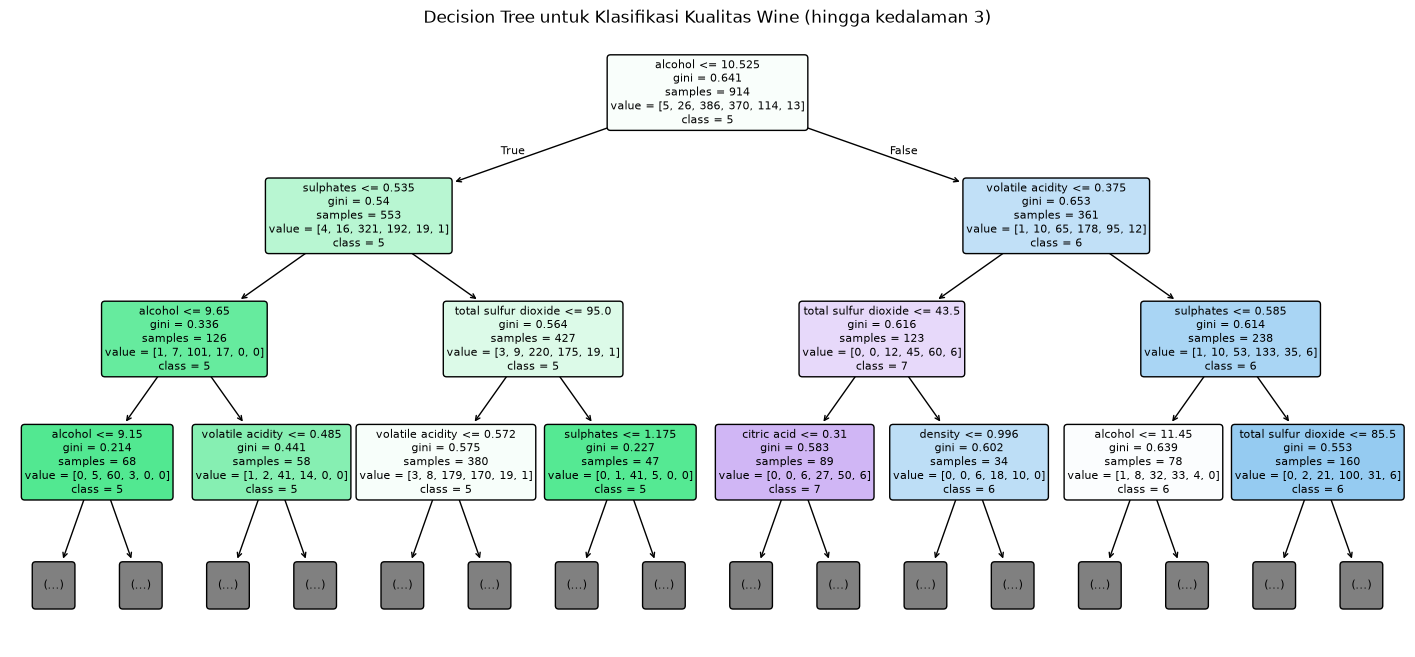

In [7]:
plt.figure(figsize=(18, 8))
plot_tree(
    best_tree,
    feature_names=X.columns,
    class_names=[str(label) for label in best_tree.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree untuk Klasifikasi Kualitas Wine (hingga kedalaman 3)")
plt.show()

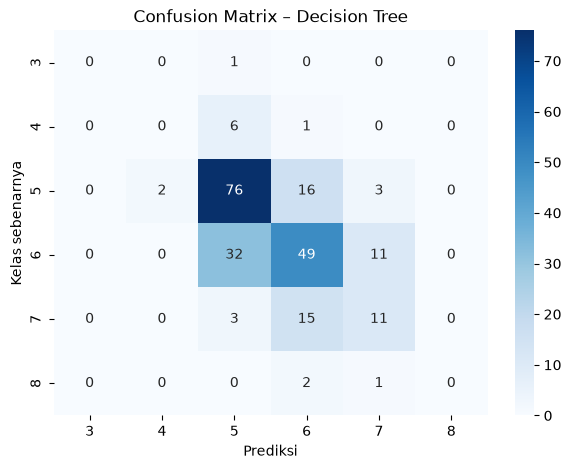

In [8]:
cm = confusion_matrix(y_test, best_pred, labels=best_tree.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=best_tree.classes_,
    yticklabels=best_tree.classes_
)
plt.xlabel("Prediksi")
plt.ylabel("Kelas sebenarnya")
plt.title("Confusion Matrix – Decision Tree")
plt.show()

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.